In [5]:
# =========================================================
# HOTSPOTS 3D — partículas que crasharam na estrela
# χ = 180°, com a estrela como esfera 3D
# =========================================================
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ---------- Configuração ----------
CSV_FILE   = "particles_all_runs.csv"
ALPHA_VAL  = 10000
ANGLE_DEG  = 180
STATUS     = "Crashed"
R_STAR     = 1.0

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
d = df[(df.angle_deg == ANGLE_DEG) &
       (df.alpha == ALPHA_VAL) &
       (df.status == STATUS)].copy()

print(f"Partículas {STATUS} em χ={ANGLE_DEG}°, α={ALPHA_VAL}: {len(d)}")

if len(d) == 0:
    raise ValueError("Nenhuma partícula encontrada. Ajuste os filtros.")

# ---------- Coordenadas das partículas ----------
# Para Crashed, a posição final é sobre a superfície da estrela (r ≈ R)
xf = d.xf.values
yf = d.yf.values
zf = d.zf.values
gamma = d.gamma_final.values

# Normaliza para garantir que os pontos estão exatamente em r = R
r = np.sqrt(xf**2 + yf**2 + zf**2)
xf_n = xf / r * R_STAR
yf_n = yf / r * R_STAR
zf_n = zf / r * R_STAR

# Coordenadas esféricas para estatística
theta_f = np.degrees(np.arccos(np.clip(zf_n / R_STAR, -1, 1)))
phi_f   = np.degrees(np.arctan2(yf_n, xf_n))

print(f"θ_f mediana: {np.median(theta_f):.1f}°")
print(f"θ_f range:   {theta_f.min():.1f}° / {theta_f.max():.1f}°")
print(f"Fracção no HN (θ_f < 90°): {(theta_f < 90).mean():.3f}")
print(f"Fracção no HS (θ_f > 90°): {(theta_f > 90).mean():.3f}")

# =========================================================
# FIGURA
# =========================================================
fig = go.Figure()

# ---------- Estrela 3D ----------
u, v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
xs = R_STAR * np.cos(u) * np.sin(v)
ys = R_STAR * np.sin(u) * np.sin(v)
zs = R_STAR * np.cos(v)

fig.add_trace(go.Surface(
    x=xs, y=ys, z=zs,
    colorscale=[[0, 'lightgray'], [1, 'lightgray']],
    showscale=False,
    opacity=0.9,
    name='star',
    hoverinfo='skip',
    lighting=dict(ambient=0.7, diffuse=0.6, specular=0.1),
))

# ---------- Partículas que crasharam ----------
log_gamma = np.log10(np.clip(gamma, 1, None))

fig.add_trace(go.Scatter3d(
    x=xf_n, y=yf_n, z=zf_n,
    mode='markers',
    marker=dict(
        size=5,
        color=log_gamma,
        colorscale='Plasma',
        cmin=log_gamma.min(),
        cmax=log_gamma.max(),
        colorbar=dict(title=r'log10(γ)', thickness=15, len=0.6),
        opacity=0.85,
        line=dict(width=0),
    ),
    name=f'{STATUS} (N={len(d)})',
    text=[f"θ={t:.1f}°, φ={p:.1f}°, γ={g:.1f}"
          for t, p, g in zip(theta_f, phi_f, gamma)],
    hovertemplate="x: %{x:.3f}<br>y: %{y:.3f}<br>z: %{z:.3f}<br>%{text}<extra></extra>",
))

# ---------- Eixos ----------
L = 1.5
fig.add_trace(go.Scatter3d(
    x=[0, 0], y=[0, 0], z=[-L, L],
    mode='lines',
    line=dict(color='black', width=4, dash='dot'),
    name='rotation axis (z)',
))

Xt = np.radians(ANGLE_DEG)
fig.add_trace(go.Scatter3d(
    x=[-L*np.sin(Xt), L*np.sin(Xt)],
    y=[0, 0],
    z=[-L*np.cos(Xt), L*np.cos(Xt)],
    mode='lines',
    line=dict(color='red', width=5, dash='dash'),
    name=f'magnetic axis (χ={ANGLE_DEG}°)',
))

# Eixos X, Y, Z como linhas guia
for vec, col, name in [((1,0,0), 'blue', 'X'),
                        ((0,1,0), 'green', 'Y')]:
    fig.add_trace(go.Scatter3d(
        x=[-vec[0]*L, vec[0]*L],
        y=[-vec[1]*L, vec[1]*L],
        z=[-vec[2]*L, vec[2]*L],
        mode='lines',
        line=dict(color=col, width=2, dash='dot'),
        opacity=0.3,
        name=f'{name} axis',
    ))

# =========================================================
# LAYOUT
# =========================================================
fig.update_layout(
    scene=dict(
        xaxis=dict(title='X (R)', range=[-L, L]),
        yaxis=dict(title='Y (R)', range=[-L, L]),
        zaxis=dict(title='Z (R)', range=[-L, L]),
        aspectmode='cube',
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.0)),
    ),
    title=dict(
        text=f'Impact hotspots on the stellar surface — '
             f'χ = {ANGLE_DEG}°, α = {ALPHA_VAL}  (N = {len(d)})',
        x=0.5,
    ),
    width=950, height=900,
    legend=dict(x=0.02, y=0.98, bgcolor='rgba(255,255,255,0.85)'),
)

fig.show()

Partículas Crashed em χ=180°, α=10000: 570
θ_f mediana: 43.4°
θ_f range:   23.6° / 156.4°
Fracção no HN (θ_f < 90°): 0.525
Fracção no HS (θ_f > 90°): 0.475


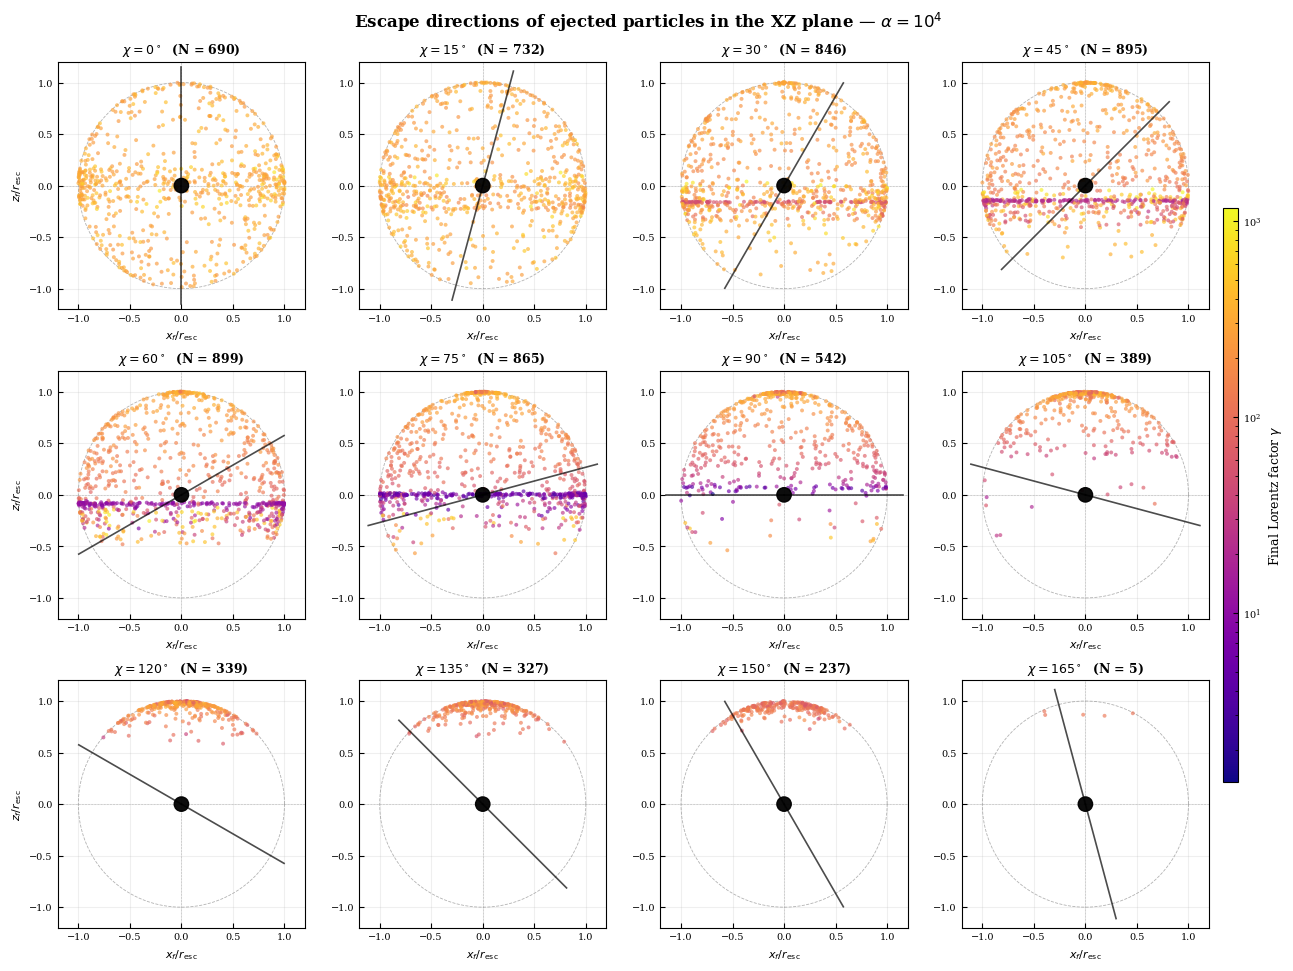

Salvo: escape_directions_alpha10000_with_star.pdf


In [2]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE + ESTRELA
# α fixo, 12 ângulos, cor = gamma final
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

# ---------- Carrega CSV ----------
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

if len(df_alpha):
    vmin = max(df_alpha.gamma_final.min(), 1.0)
    vmax = max(df_alpha.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

# ---------- Layout 3×4 ----------
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# Raio da estrela em unidades de r_esc (r_esc = 3 r_lc ≈ 14.35, R = 1)
r_esc = 3.0 / 0.209
R_norm = 1.0 / r_esc   # raio da estrela normalizado pela esfera de escape

theta_circ = np.linspace(0, 2*np.pi, 400)

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = d.xf / r_norm
    zf_n = d.zf / r_norm

    # Scatter em XZ
    ax.scatter(xf_n, zf_n,
               c=d.gamma_final.values,
               cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Círculo unitário (esfera de escape)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Estrela preta no centro (raio R_norm)
    ax.add_patch(plt.Circle((0, 0), R_norm, color='black',
                            zorder=5, alpha=0.95))

    # Eixo magnético
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)

    # Linhas guia
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_alpha{ALPHA_VAL}_with_star.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: escape_directions_alpha{ALPHA_VAL}_with_star.pdf")

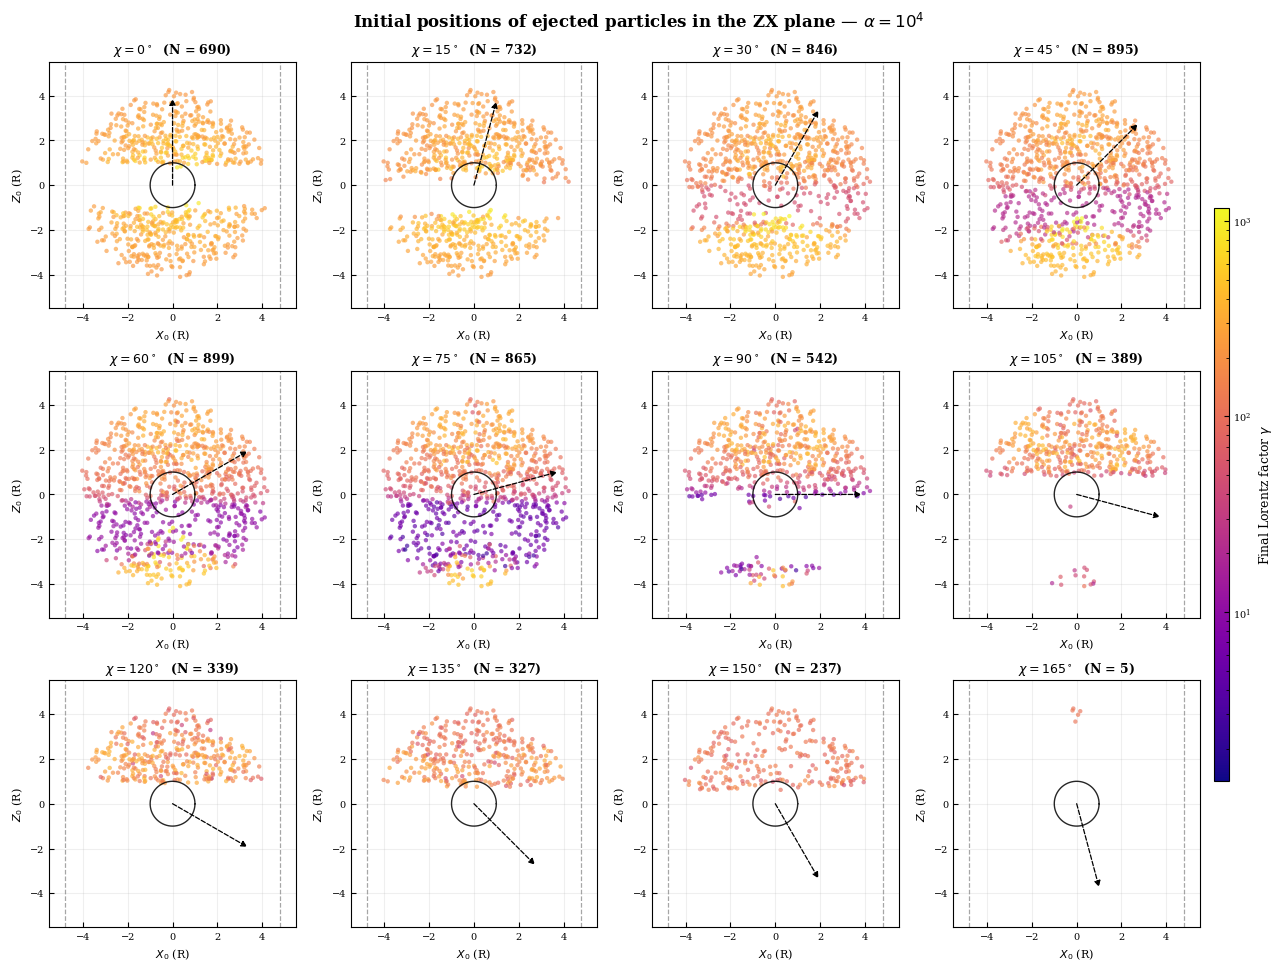

In [6]:
# ==========================================
# GRADE 3×4 — PROJEÇÃO ZX A PARTIR DO CSV
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

POINT_SIZE   = 10
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

om = 0.209
r_lc_val = 1.0 / om

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)

# Filtra alpha
df_alpha = df[df.alpha == ALPHA_VAL]

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

theta_circ = np.linspace(0, 2*np.pi, 400)
ZOOM_LIM = r_lc_val * 1.15

# Limites globais de gamma (para colorbar consistente)
d_all = df_alpha[df_alpha.status == "Ejected"]
if len(d_all):
    vmin = max(d_all.gamma_final.min(), 1.0)
    vmax = max(d_all.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]

    d = df_alpha[(df_alpha.angle_deg == ang) &
                 (df_alpha.status == "Ejected")]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\nχ={ang}°",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    x0    = d.x0.values
    z0    = d.z0.values
    gamas = d.gamma_final.values
    N = len(gamas)

    # Scatter em ZX
    ax.scatter(x0, z0, c=gamas, cmap=CMAP,
               norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Estrela
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='black', lw=1.0, alpha=0.85, zorder=4)

    # Light cylinder — retas verticais em ZX
    ax.axvline( r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)
    ax.axvline(-r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)

    # Seta do dipolo (direção (sin χ, cos χ) em ZX)
    chi_rad = np.radians(ang)
    L_dip = ZOOM_LIM * 0.7
    dx = np.sin(chi_rad) * L_dip
    dz = np.cos(chi_rad) * L_dip

    arrow = FancyArrowPatch(
        (0, 0), (dx, dz),
        arrowstyle='-|>', color='black',
        lw=0.9, linestyle='--', mutation_scale=9,
        shrinkA=0, shrinkB=0, zorder=5,
    )
    ax.add_patch(arrow)

    # Estética
    ax.set_xlabel(r'$X_0$ (R)', fontsize=8)
    ax.set_ylabel(r'$Z_0$ (R)', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {N})',
                 fontweight='bold', fontsize=9)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2, zorder=0)
    ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP,
                           norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Initial positions of ejected particles in the ZX plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig('initial_positions.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)

plt.show()

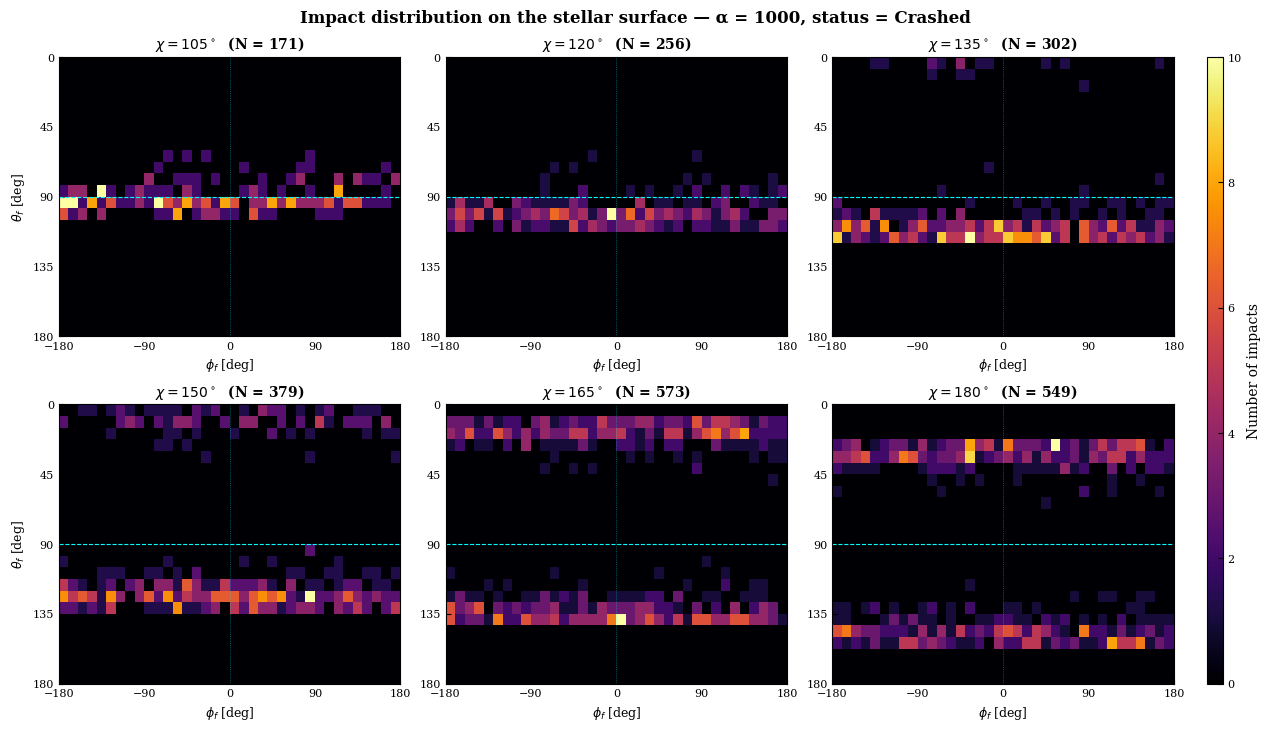

Salvo: hotspots_2d_chi105to180_alpha1000.pdf


In [9]:
# =========================================================
# HOTSPOTS — histograma 2D em (φ_f, θ_f)
# Ângulos: 105, 120, 135, 150, 165, 180
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1000
STATUS    = "Crashed"
ANGLES    = [105, 120, 135, 150, 165, 180]

N_BINS_PH = 36
N_BINS_TH = 24

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)

# ---------- Layout 2×3 ----------
N_ROWS = 2
N_COLS = 3

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(4.2 * N_COLS, 3.6 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# Guarda o último histograma para a colorbar
h_last = None

for k, ang in enumerate(ANGLES):
    ax = axes[k]
    d = df[(df.angle_deg == ang) &
           (df.alpha == ALPHA_VAL) &
           (df.status == STATUS)]

    if len(d) == 0:
        ax.text(0.5, 0.5, f'No {STATUS}\nχ={ang}°',
                ha='center', va='center', transform=ax.transAxes,
                fontsize=9)
        ax.set_axis_off()
        continue

    # Coordenadas esféricas finais
    xf = d.xf.values; yf = d.yf.values; zf = d.zf.values
    r = np.sqrt(xf**2 + yf**2 + zf**2)
    theta_f = np.degrees(np.arccos(np.clip(zf/r, -1, 1)))
    phi_f   = np.degrees(np.arctan2(yf, xf))

    # Histograma 2D
    h = ax.hist2d(phi_f, theta_f,
                  bins=[N_BINS_PH, N_BINS_TH],
                  range=[[-180, 180], [0, 180]],
                  cmap='inferno')
    h_last = h

    # Equador
    ax.axhline(90, color='cyan', lw=0.8, ls='--')
    # Linhas verticais em φ = 0 e ±180 (plano XZ)
    ax.axvline(0, color='cyan', lw=0.5, ls=':', alpha=0.6)
    ax.axvline(-180, color='cyan', lw=0.5, ls=':', alpha=0.6)
    ax.axvline(180, color='cyan', lw=0.5, ls=':', alpha=0.6)

    # Estética
    ax.set_xlabel(r'$\phi_f$ [deg]', fontsize=9)
    if k % N_COLS == 0:
        ax.set_ylabel(r'$\theta_f$ [deg]', fontsize=9)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontsize=10, fontweight='bold')
    ax.invert_yaxis()          # polo norte em cima
    ax.set_xlim(-180, 180)
    ax.set_ylim(180, 0)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([0, 45, 90, 135, 180])
    ax.tick_params(labelsize=8)

# ---------- Colorbar ----------
if h_last is not None:
    cbar = fig.colorbar(h_last[3], ax=axes.tolist(),
                        fraction=0.018, pad=0.02, aspect=40)
    cbar.set_label('Number of impacts', fontsize=10)

fig.suptitle(f'Impact distribution on the stellar surface — '
             f'α = {int(ALPHA_VAL)}, status = {STATUS}',
             fontsize=12, fontweight='bold')

plt.savefig(f'hotspots_2d_chi105to180_alpha{int(ALPHA_VAL)}.pdf',
            bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: hotspots_2d_chi105to180_alpha{int(ALPHA_VAL)}.pdf")